# Ảnh xám: bình thường vs sau khi ăn power pellet

Mục đích: xem mạng "nhìn thấy" gì khi ma đang choáng (frightened). So sánh khung RGB gốc với khung xám 84x84 mà mạng thực sự nhận.

In [1]:
import cv2
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
import ale_py  # noqa: F401

ENV_ID = "ALE/MsPacman-v5"
KW = dict(frameskip=4, repeat_action_probability=0.0, full_action_space=False)

## 1. Thu khung hình
Hai env cùng seed, chạy cùng chuỗi hành động ngẫu nhiên (ALE tất định khi `repeat_action_probability=0`): một env trả RGB, một env trả xám. Power pellet cho 40 điểm, nên bước nào có reward 40 (hoặc 50 nếu ăn cả viên thường) là lúc ăn power pellet.
Sau đó lưu khung ở các mốc `OFFSETS` (tính theo bước agent, 1 bước = 4 frame ALE).

In [2]:
OFFSETS = [0, 10, 30, 60]   # sau khi ăn power pellet; choáng kéo dài khoảng 90 bước agent ở màn 1

def collect(max_episodes=200, seed=0):
    rng = np.random.default_rng(seed)
    for ep in range(max_episodes):
        e_rgb = gym.make(ENV_ID, obs_type="rgb", **KW)
        e_gray = gym.make(ENV_ID, obs_type="grayscale", **KW)
        rgb, _ = e_rgb.reset(seed=ep)
        gray, _ = e_gray.reset(seed=ep)
        before = (rgb, gray)
        hit, after, t = None, [], 0
        while True:
            a = int(rng.integers(e_rgb.action_space.n))
            rgb, r, term, trunc, _ = e_rgb.step(a)
            gray, _, _, _, _ = e_gray.step(a)
            if hit is None:
                if r in (40.0, 50.0):
                    hit = t
                    after.append((rgb, gray))
                else:
                    before = (rgb, gray)
            else:
                k = t - hit
                if k in OFFSETS[1:]:
                    after.append((rgb, gray))
            t += 1
            if term or trunc or (hit is not None and t - hit > OFFSETS[-1]):
                break
        e_rgb.close(); e_gray.close()
        if hit is not None and len(after) == len(OFFSETS):
            print(f"episode {ep}: ăn power pellet ở bước {hit}")
            return before, after
    raise RuntimeError("không bắt được power pellet, tăng max_episodes")

before, after = collect()

episode 17: ăn power pellet ở bước 185


## 2. Khung gốc (RGB) vs khung mạng nhìn thấy (xám 84x84)
Hàng trên: RGB 210x160. Hàng dưới: xám resize 84x84 bằng `INTER_AREA`, giống `AtariPreprocessing`.

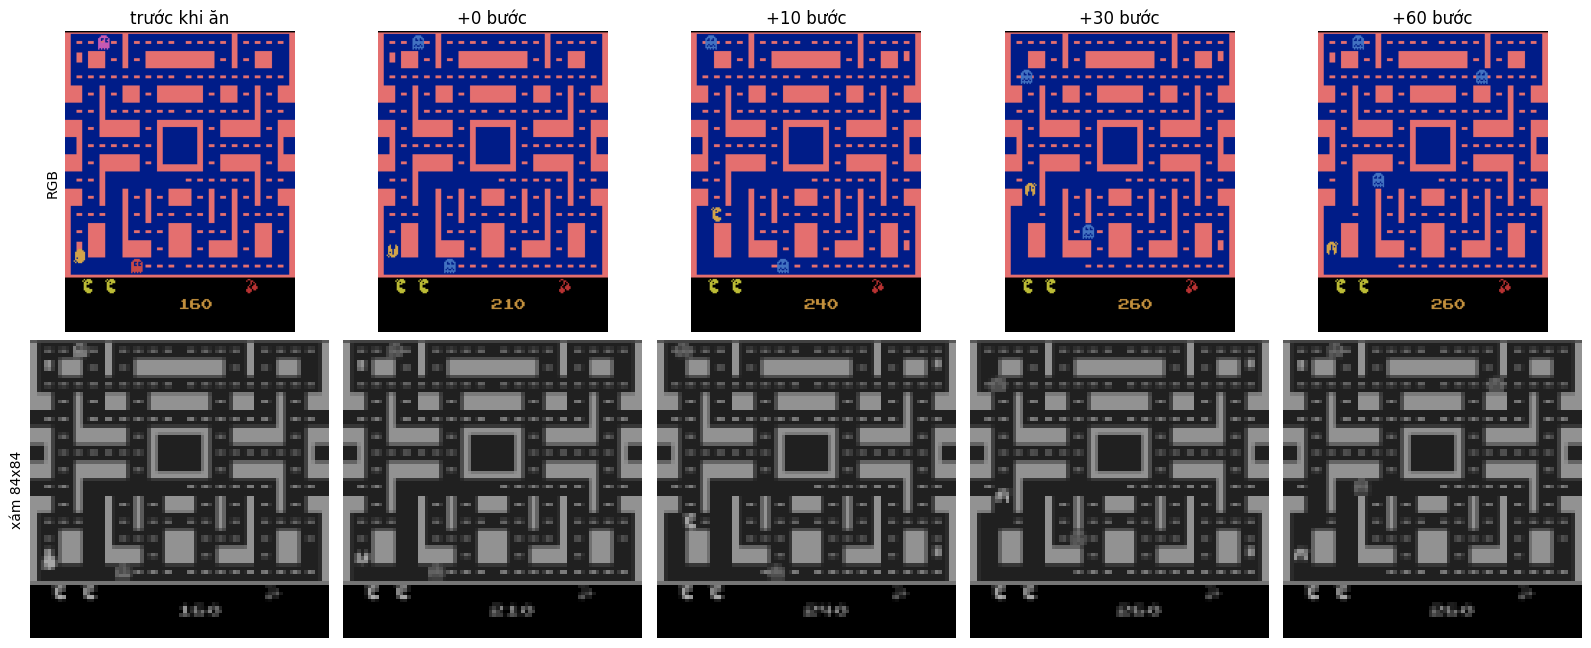

In [3]:
def to84(gray):
    return cv2.resize(gray, (84, 84), interpolation=cv2.INTER_AREA)

frames = [("trước khi ăn", *before)] + [(f"+{k} bước", *f) for k, f in zip(OFFSETS, after)]
fig, axes = plt.subplots(2, len(frames), figsize=(3.2 * len(frames), 6.6))
for i, (title, rgb, gray) in enumerate(frames):
    axes[0, i].imshow(rgb); axes[0, i].set_title(title)
    axes[1, i].imshow(to84(gray), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    for ax in axes[:, i]: ax.axis("off")
axes[0, 0].text(-0.02, 0.5, "RGB", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center")
axes[1, 0].text(-0.02, 0.5, "xám 84x84", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center")
plt.tight_layout(); plt.show()

## 3. Cái gì thay đổi sau khi ăn?
Ảnh hiệu |sau − trước| trên khung xám 84x84. Phần sáng là pixel đổi giá trị. Nếu ma choáng đổi màu mà ảnh xám gần như không đổi ở vị trí con ma thì màu đang bị mất thông tin.

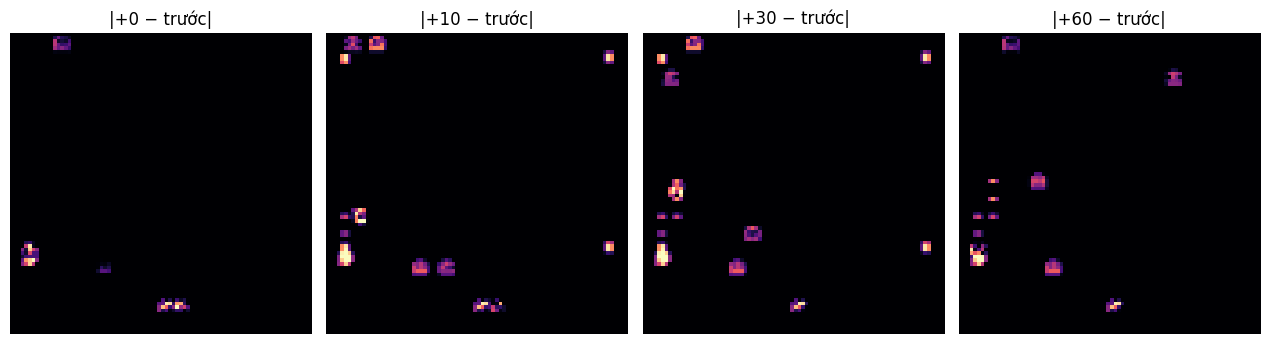

In [4]:
ref = to84(before[1]).astype(int)
fig, axes = plt.subplots(1, len(after), figsize=(3.2 * len(after), 3.4))
for ax, k, (_, g) in zip(axes, OFFSETS, after):
    ax.imshow(np.abs(to84(g).astype(int) - ref), cmap="magma", vmin=0, vmax=120, interpolation="nearest")
    ax.set_title(f"|+{k} − trước|"); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Độ sáng xám của ma choáng vs ma thường vs nền
Lấy khung RGB ở mốc +30 (đang choáng), tìm pixel xanh dương của ma choáng và đổi sang độ xám theo công thức ITU-R 601 (giống ALE). So với độ xám của tường và nền.

In [5]:
rgb = after[2][0].astype(int)
gray = after[2][1]
blue = (rgb[..., 2] > 150) & (rgb[..., 0] < 110) & (rgb[..., 1] < 150)   # xanh dương của ma choáng
print("số pixel xanh (ma choáng):", int(blue.sum()))
if blue.any():
    print("độ xám của ma choáng: mean %.0f" % gray[blue].mean())
print("độ xám nền (đen): %.0f" % gray[2:10, 2:10].mean())
vals, counts = np.unique(gray[20:170], return_counts=True)
top = vals[np.argsort(-counts)[:6]]
print("các mức xám phổ biến trong mê cung:", sorted(top.tolist()))

số pixel xanh (ma choáng): 116
độ xám của ma choáng: mean 109
độ xám nền (đen): 68
các mức xám phổ biến trong mê cung: [32, 109, 146, 167]
